# Session 12: Data Visualization in Python

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-12_matplotlib_basics.py`

In [2]:
"""
Session 12 · Example 1: Matplotlib fundamentals - the four core chart types
---------------------------------------------------------------------------
Shows the object-oriented interface (fig, ax), labels, legends, colours,
annotations and a 2 x 2 grid of subplots saved to one PNG file.
Run:  python session-12_matplotlib_basics.py
"""
import matplotlib
matplotlib.use("Agg")                    # draw to files (no window); remove this line to see windows
import matplotlib.pyplot as plt
import numpy as np

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
# Illustrative average monthly maximum temperatures (deg C), rounded, for two cities
karachi = [26, 28, 32, 35, 36, 35, 33, 32, 33, 35, 32, 28]
lahore = [19, 22, 27, 33, 38, 40, 36, 35, 34, 32, 27, 21]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))          # a Figure with 4 Axes
fig.suptitle("Four core chart types", fontsize=14, fontweight="bold")

# 1. LINE chart: change over an ordered axis (time)
ax = axes[0, 0]
ax.plot(months, karachi, marker="o", color="#FF6B1A", label="Karachi")
ax.plot(months, lahore, marker="s", linestyle="--", color="#A78BFA", label="Lahore")
ax.annotate("Lahore peaks in June", xy=(5, 40), xytext=(6.3, 25), arrowprops={"arrowstyle": "->"})
ax.set_title("Line: monthly max temperature"); ax.set_ylabel("deg C"); ax.legend()
ax.tick_params(axis="x", rotation=45); ax.grid(alpha=0.3)

# 2. BAR chart: compare categories
langs = ["Python", "SQL", "JavaScript", "Java", "C#"]
votes = [48, 31, 27, 14, 9]                              # a class survey: favourite language
ax = axes[0, 1]
bars = ax.bar(langs, votes, color=["#FF6B1A", "#FCD34D", "#A78BFA", "#F43F5E", "#6B7280"])
ax.bar_label(bars)                                        # value on top of each bar
ax.set_title("Bar: favourite language (n = 129)"); ax.set_ylabel("students")

# 3. HISTOGRAM: distribution of one numeric variable
rng = np.random.default_rng(1)
marks = np.clip(rng.normal(68, 12, 300), 0, 100)
ax = axes[1, 0]
ax.hist(marks, bins=15, color="#FCD34D", edgecolor="black")
ax.axvline(marks.mean(), color="#F43F5E", linestyle="--", label=f"mean {marks.mean():.1f}")
ax.set_title("Histogram: exam marks (300 students)"); ax.set_xlabel("mark"); ax.legend()

# 4. SCATTER plot: relationship between two numeric variables
hours = rng.uniform(0, 10, 80)
score = 40 + 5 * hours + rng.normal(0, 6, 80)
ax = axes[1, 1]
sc = ax.scatter(hours, score, c=score, cmap="plasma", s=30)
m, b = np.polyfit(hours, score, 1)                       # best-fit line (Session 15 explains it)
xs = np.linspace(0, 10, 2)
ax.plot(xs, m * xs + b, color="black", linewidth=1)
fig.colorbar(sc, ax=ax, label="score")
ax.set_title(f"Scatter: study hours vs score (r = {np.corrcoef(hours, score)[0, 1]:.2f})")
ax.set_xlabel("hours per week"); ax.set_ylabel("score")

fig.tight_layout()
fig.savefig("session-12_matplotlib_basics.png", dpi=100)
print("Saved session-12_matplotlib_basics.png")
print(f"Figure size {fig.get_size_inches()} inches, {len(fig.axes)} axes (4 plots + 1 colour bar)")
print(f"Histogram: mean {marks.mean():.1f}, std {marks.std():.1f}; fitted line: score = {m:.1f} x hours + {b:.1f}")

Saved session-12_matplotlib_basics.png
Figure size [10.  7.] inches, 5 axes (4 plots + 1 colour bar)
Histogram: mean 66.7, std 11.0; fitted line: score = 4.9 x hours + 41.2


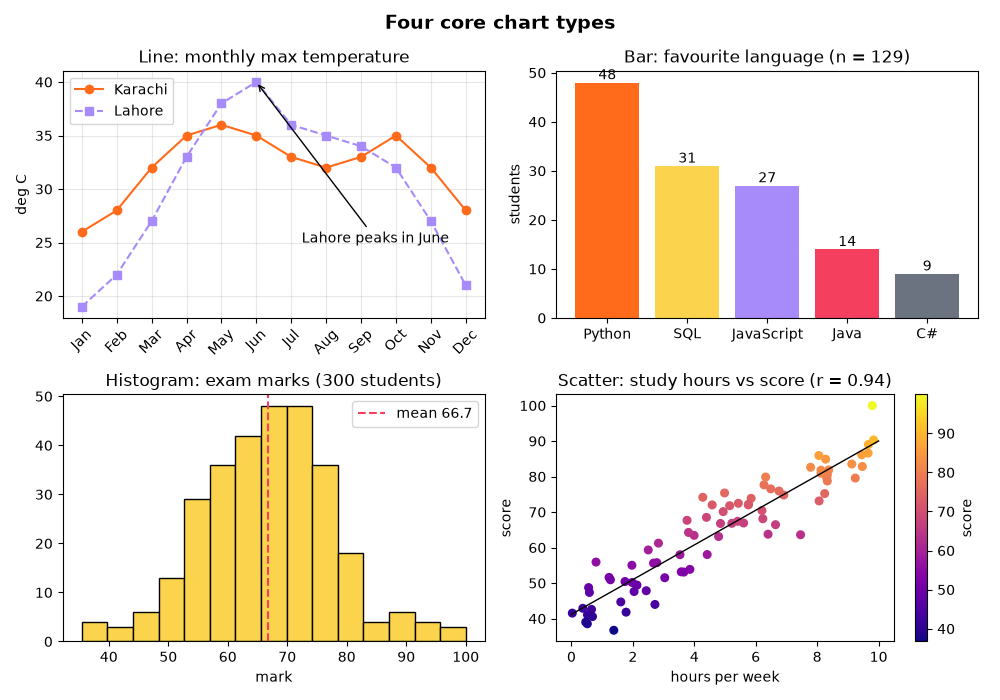

In [3]:
from IPython.display import Image, display
display(Image(filename='session-12_matplotlib_basics.png'))  # chart saved by the cell above

## Example: `session-12_seaborn_pandas.py`

In [4]:
"""
Session 12 · Example 2: statistical charts with seaborn and pandas plotting
---------------------------------------------------------------------------
seaborn works directly with DataFrames: give it the table and column names.
The dataset is generated with a fixed seed (no internet download needed).
Run:  python session-12_seaborn_pandas.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

rng = np.random.default_rng(12)
n = 240
df = pd.DataFrame({
    "program": rng.choice(["AI", "Data Science", "Web Dev"], n, p=[0.4, 0.35, 0.25]),
    "shift": rng.choice(["Morning", "Evening"], n),
    "study_hours": rng.gamma(4, 2, n).round(1),
})
df["attendance"] = np.clip(rng.normal(82, 9, n), 40, 100).round(0)
df["score"] = np.clip(18 + 3.0 * df["study_hours"] + 0.3 * df["attendance"]
                      + df["program"].map({"AI": 3, "Data Science": 1, "Web Dev": -2}) + rng.normal(0, 7, n), 0, 100).round(0)
print(df.head(), "\n")
print(df.groupby("program")[["study_hours", "score"]].mean().round(1), "\n")

sns.set_theme(style="whitegrid", palette=["#FF6B1A", "#A78BFA", "#F43F5E"])
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
sns.histplot(data=df, x="score", hue="program", kde=True, element="step", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of scores (histogram + KDE)")
sns.boxplot(data=df, x="program", y="score", hue="shift", ax=axes[0, 1])
axes[0, 1].set_title("Box plot: score by program and shift")
sns.violinplot(data=df, x="program", y="study_hours", ax=axes[0, 2], inner="quartile")
axes[0, 2].set_title("Violin: study hours by program")
sns.scatterplot(data=df, x="study_hours", y="score", hue="program", alpha=0.7, ax=axes[1, 0])
sns.regplot(data=df, x="study_hours", y="score", scatter=False, color="black", ax=axes[1, 0])
axes[1, 0].set_title("Scatter + regression line")
sns.countplot(data=df, x="program", hue="shift", ax=axes[1, 1])
axes[1, 1].set_title("Count plot: students per group")
corr = df[["study_hours", "attendance", "score"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket_r", vmin=-1, vmax=1, ax=axes[1, 2])
axes[1, 2].set_title("Heatmap: correlation matrix")
fig.tight_layout(); fig.savefig("session-12_seaborn_pandas.png", dpi=95)
print("Correlation matrix:\n", corr.round(2), "\n")

# pandas has plotting built in: DataFrame.plot(kind=...)
summary = df.pivot_table(index="program", columns="shift", values="score", aggfunc="mean")
ax = summary.plot(kind="barh", figsize=(6, 3), color=["#FCD34D", "#6B7280"], title="pandas .plot(): mean score")
ax.set_xlabel("mean score"); plt.tight_layout(); plt.savefig("session-12_seaborn_pandas_pandasplot.png", dpi=100)
print("Mean score by program and shift:\n", summary.round(1))
print("\nSaved session-12_seaborn_pandas.png and session-12_seaborn_pandas_pandasplot.png")

   program    shift  study_hours  attendance  score
0       AI  Morning         11.8        88.0   84.0
1  Web Dev  Morning         12.7        76.0   84.0
2       AI  Morning          9.2        99.0   82.0
3       AI  Morning          8.1        87.0   86.0
4       AI  Evening          1.1        81.0   39.0 

              study_hours  score
program                         
AI                    8.1   70.6
Data Science          8.1   67.5
Web Dev               7.7   63.4 



Correlation matrix:
              study_hours  attendance  score
study_hours         1.00       -0.02   0.85
attendance         -0.02        1.00   0.13
score               0.85        0.13   1.00 

Mean score by program and shift:
 shift         Evening  Morning
program                       
AI               70.9     70.3
Data Science     65.8     69.7
Web Dev          62.6     64.2

Saved session-12_seaborn_pandas.png and session-12_seaborn_pandas_pandasplot.png


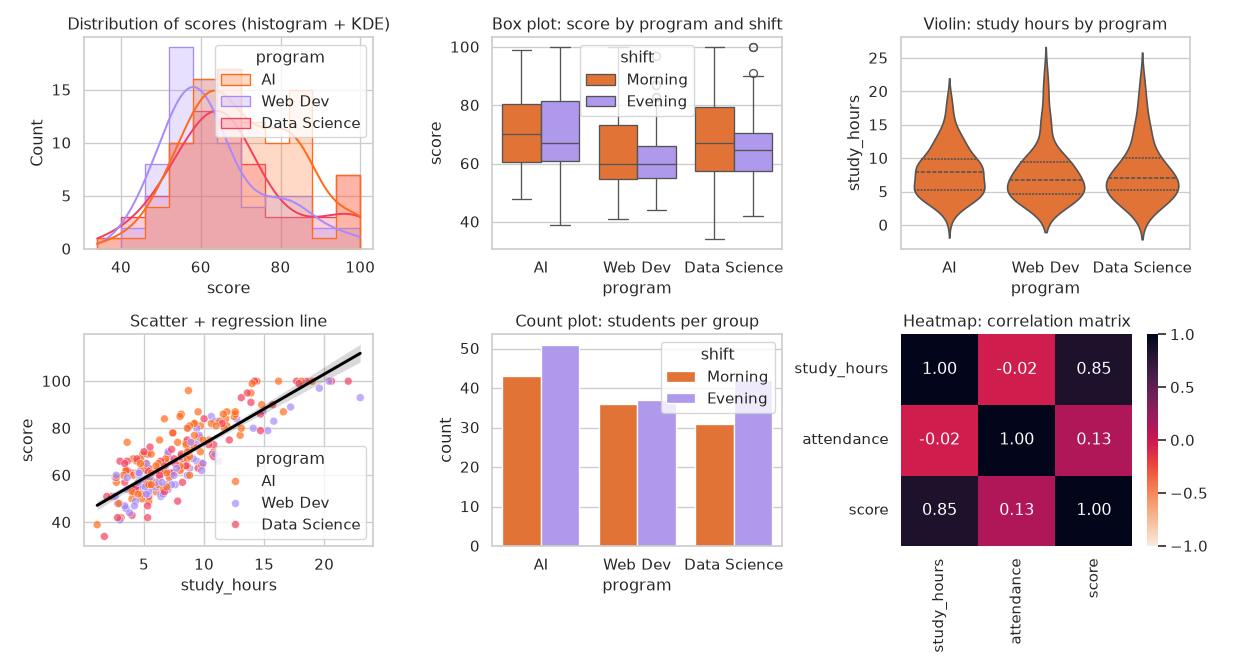

In [5]:
from IPython.display import Image, display
display(Image(filename='session-12_seaborn_pandas.png'))  # chart saved by the cell above

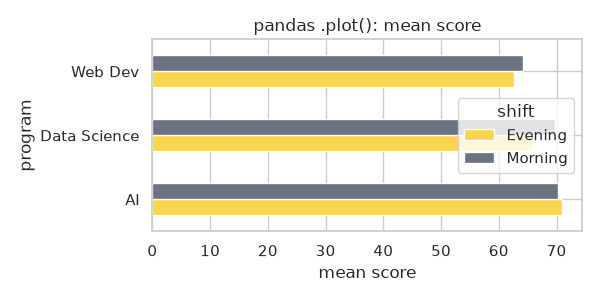

In [6]:
from IPython.display import Image, display
display(Image(filename='session-12_seaborn_pandas_pandasplot.png'))  # chart saved by the cell above

## Example: `session-12_choosing_charts.py`

In [7]:
"""
Session 12 · Example 3: choosing honest, readable charts (bad vs better)
------------------------------------------------------------------------
Three common mistakes, each shown next to a better version:
  1. a pie chart with too many slices  -> a sorted horizontal bar chart
  2. a truncated y-axis that exaggerates a difference -> an axis starting at 0
  3. a cluttered rainbow line chart     -> highlight the one series that matters
Run:  python session-12_choosing_charts.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

expenses = {"Rent": 45000, "Food": 28000, "Transport": 9000, "Utilities": 12000, "Education": 15000,
            "Health": 4000, "Phone/Internet": 3500, "Clothes": 5000, "Eating out": 6000, "Gifts": 2500,
            "Savings": 10000, "Other": 3000}
fig, axes = plt.subplots(3, 2, figsize=(11, 11))

# 1. Pie with 12 slices vs sorted bar
axes[0, 0].pie(expenses.values(), labels=expenses.keys(), textprops={"fontsize": 7})
axes[0, 0].set_title("BAD: 12-slice pie - which is bigger, Health or Clothes?")
items = sorted(expenses.items(), key=lambda kv: kv[1])
axes[0, 1].barh([k for k, _ in items], [v for _, v in items], color="#FF6B1A")
axes[0, 1].set_title("BETTER: sorted bar chart, easy to compare")
axes[0, 1].set_xlabel("Rs per month")

# 2. Truncated axis vs zero-based axis
branches, satisfaction = ["Branch A", "Branch B"], [81.2, 83.0]
axes[1, 0].bar(branches, satisfaction, color=["#A78BFA", "#F43F5E"]); axes[1, 0].set_ylim(80.5, 83.5)
axes[1, 0].set_title("MISLEADING: axis starts at 80.5 (B looks 3x better)")
axes[1, 1].bar(branches, satisfaction, color=["#A78BFA", "#F43F5E"]); axes[1, 1].set_ylim(0, 100)
for i, v in enumerate(satisfaction):
    axes[1, 1].text(i, v + 2, f"{v}%", ha="center")
axes[1, 1].set_title("HONEST: axis from 0, gap of 1.8 points")

# 3. Spaghetti chart vs highlight
rng = np.random.default_rng(3)
weeks = np.arange(1, 13)
series = {f"Product {c}": 100 + np.cumsum(rng.normal(0, 4, 12)) for c in "ABCDEFGH"}
series["Product C"] = 100 + np.cumsum(rng.normal(3, 2, 12))       # the one that grows
for name, ys in series.items():
    axes[2, 0].plot(weeks, ys, label=name)
axes[2, 0].legend(fontsize=6, ncol=2); axes[2, 0].set_title("CLUTTERED: 8 colours, the story is lost")
for name, ys in series.items():
    hl = name == "Product C"
    axes[2, 1].plot(weeks, ys, color="#FF6B1A" if hl else "#BBBBBB", linewidth=3 if hl else 1)
axes[2, 1].annotate("Product C: steady growth", xy=(12, series["Product C"][-1]), xytext=(6.5, series["Product C"][-1] - 12),
                    arrowprops={"arrowstyle": "->"})
axes[2, 1].set_title("BETTER: grey context, one highlighted series")
for ax in axes[2]:
    ax.set_xlabel("week"); ax.set_ylabel("weekly sales index")

fig.tight_layout(); fig.savefig("session-12_choosing_charts.png", dpi=90)
diff = satisfaction[1] - satisfaction[0]
print(f"Satisfaction gap: {diff:.1f} points ({diff / satisfaction[0]:.1%} relative).")
print("On the truncated axis, bar B is drawn", round((83.0 - 80.5) / (81.2 - 80.5), 1), "times taller than bar A.")
print("Largest expense:", items[-1][0], "| smallest:", items[0][0])
print(f"Product C grew {series['Product C'][-1] - 100:.0f} points in 12 weeks.")
print("Saved session-12_choosing_charts.png")

Satisfaction gap: 1.8 points (2.2% relative).
On the truncated axis, bar B is drawn 3.6 times taller than bar A.
Largest expense: Rent | smallest: Gifts
Product C grew 41 points in 12 weeks.
Saved session-12_choosing_charts.png


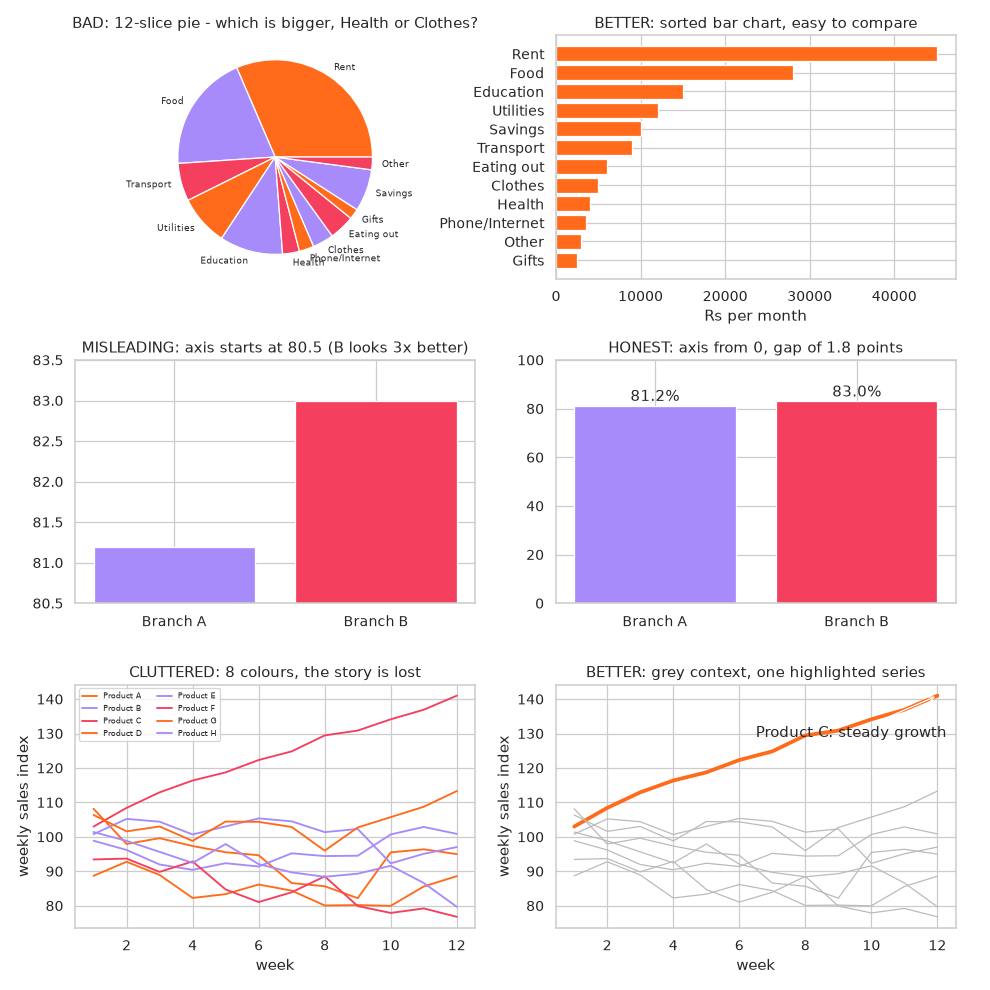

In [8]:
from IPython.display import Image, display
display(Image(filename='session-12_choosing_charts.png'))  # chart saved by the cell above

## Example: `session-12_problem_weather_dashboard.py`

In [9]:
"""
Session 12 · Real-life problem: a one-page weather and air-quality dashboard
--------------------------------------------------------------------------
PROBLEM
A city environment office has one year of daily readings (temperature,
humidity, AQI = air-quality index) and wants ONE image for its monthly
meeting that answers:
  1. How do temperature and AQI change through the year?      (line chart)
  2. How often is the air "unhealthy" (AQI > 150)?             (histogram + threshold)
  3. Which months are worst for air quality?                   (box plot per month)
  4. Are hot, dry days cleaner or dirtier?                      (scatter + correlation)
The numbers are SYNTHETIC (generated with a seed) but shaped like a coastal
South Asian city: hot humid summers, cooler dry winters with worse smog.
Run:  python session-12_problem_weather_dashboard.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
days = pd.date_range("2025-01-01", "2025-12-31", freq="D")
t = np.arange(len(days))
season = np.cos(2 * np.pi * (t - 15) / 365)                      # +1 in mid-January, -1 in mid-July
df = pd.DataFrame({
    "date": days,
    "temp": (31 - 5 * season + rng.normal(0, 1.6, len(days))).round(1),
    "humidity": np.clip(62 - 14 * season + rng.normal(0, 7, len(days)), 15, 100).round(0),
})
df["aqi"] = np.clip(110 + 55 * season - 0.6 * (df["humidity"] - 60) + rng.gamma(2, 12, len(days)), 20, 400).round(0)
df["month"] = df["date"].dt.strftime("%b")
order = list(pd.date_range("2025-01-01", periods=12, freq="MS").strftime("%b"))

monthly = df.groupby("month", sort=False)[["temp", "aqi", "humidity"]].mean().reindex(order).round(1)
unhealthy = (df["aqi"] > 150).sum()
r_temp, r_hum = df["aqi"].corr(df["temp"]), df["aqi"].corr(df["humidity"])
print("Monthly means:\n", monthly.T.to_string())
print(f"\nUnhealthy days (AQI > 150): {unhealthy} of {len(df)} ({unhealthy / len(df):.0%})")
print("Worst month by median AQI:", df.groupby("month")["aqi"].median().idxmax(),
      "| best:", df.groupby("month")["aqi"].median().idxmin())
print(f"Correlation AQI-temperature r = {r_temp:.2f}, AQI-humidity r = {r_hum:.2f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Weather and air quality, 2025 (synthetic demo data)", fontsize=14, fontweight="bold")

ax = axes[0, 0]                                                    # 1. dual-axis line chart
roll = df.set_index("date")[["temp", "aqi"]].rolling(14, center=True).mean()
ax.plot(roll.index, roll["temp"], color="#FF6B1A", label="temperature (14-day avg)")
ax.set_ylabel("deg C", color="#FF6B1A")
ax2 = ax.twinx()
ax2.plot(roll.index, roll["aqi"], color="#A78BFA", label="AQI (14-day avg)")
ax2.set_ylabel("AQI", color="#A78BFA")
ax.set_title("Seasonal pattern: hot summers, smoggy winters")
ax.legend(loc="upper left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)

ax = axes[0, 1]                                                    # 2. histogram with threshold
ax.hist(df["aqi"], bins=30, color="#FCD34D", edgecolor="black")
ax.axvline(150, color="#F43F5E", linestyle="--", linewidth=2)
ax.text(0.97, 0.95, f"AQI > 150 (unhealthy):\n{unhealthy} days", color="#F43F5E", ha="right", va="top",
        transform=ax.transAxes, bbox={"facecolor": "white", "edgecolor": "#F43F5E"})
ax.set_title("How often is the air unhealthy?"); ax.set_xlabel("daily AQI")

ax = axes[1, 0]                                                    # 3. box plot per month
ax.boxplot([df.loc[df["month"] == m, "aqi"] for m in order], tick_labels=order)
ax.axhline(150, color="#F43F5E", linestyle="--", linewidth=1)
ax.set_title("AQI by month (box = middle 50 % of days)"); ax.set_ylabel("AQI")

ax = axes[1, 1]                                                    # 4. scatter coloured by humidity
sc = ax.scatter(df["temp"], df["aqi"], c=df["humidity"], cmap="viridis", s=12)
fig.colorbar(sc, ax=ax, label="humidity %")
ax.set_title(f"Hotter, more humid days are cleaner (r = {r_temp:.2f})")
ax.set_xlabel("temperature (deg C)"); ax.set_ylabel("AQI")

fig.tight_layout()
fig.savefig("session-12_problem_weather_dashboard.png", dpi=90)
print("Saved session-12_problem_weather_dashboard.png")

Monthly means:
 month       Jan    Feb    Mar    Apr    May   Jun   Jul   Aug    Sep    Oct    Nov    Dec
temp       26.0   27.6   28.1   30.7   33.5  35.6  36.0  35.5   33.2   31.6   28.2   26.8
aqi       199.5  184.7  173.1  135.1  101.3  77.1  67.6  80.7  101.1  130.1  157.7  185.5
humidity   48.0   51.0   54.7   60.4   69.0  74.9  75.8  74.1   69.9   59.9   55.8   50.7

Unhealthy days (AQI > 150): 143 of 365 (39%)
Worst month by median AQI: Jan | best: Jul
Correlation AQI-temperature r = -0.85, AQI-humidity r = -0.81


Saved session-12_problem_weather_dashboard.png


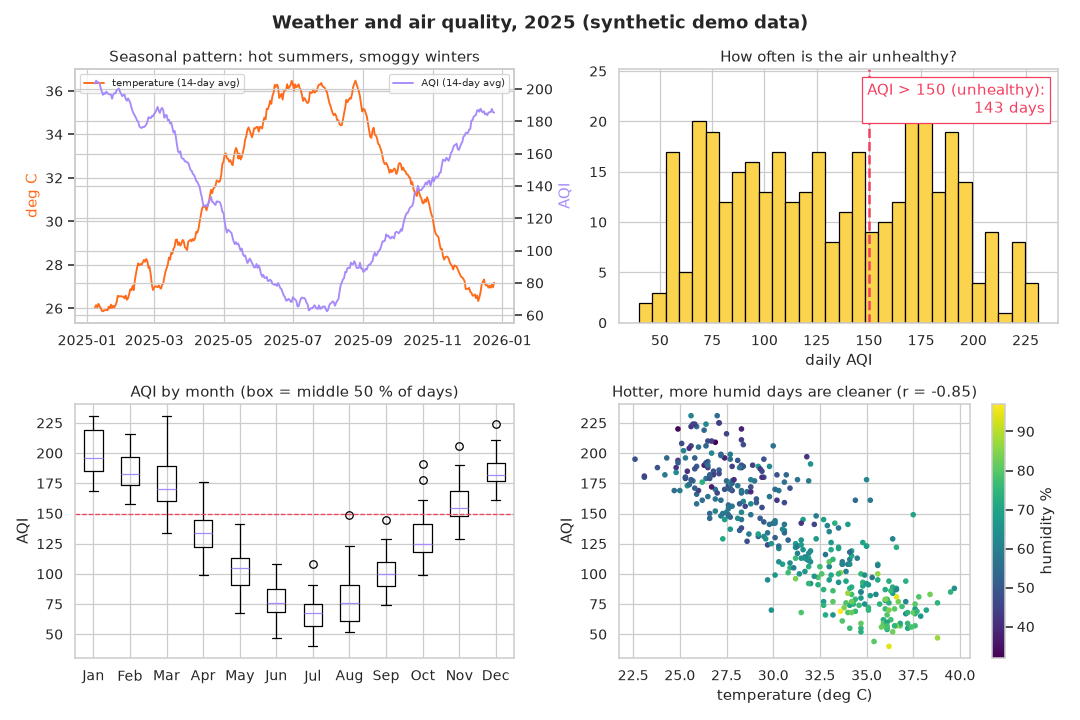

In [10]:
from IPython.display import Image, display
display(Image(filename='session-12_problem_weather_dashboard.png'))  # chart saved by the cell above

## Example: `session-12_project_car_market_eda.py`

In [11]:
"""
Session 12 · Mini project: visual exploratory analysis of a used-car market
---------------------------------------------------------------------------
A buyer (or a pricing model, Session 15) needs to understand used-car prices.
The project builds a synthetic listings dataset (seeded), then answers six
questions with six charts arranged in one dashboard, printing the numbers
behind each chart so every visual claim can be checked.
Run:  python session-12_project_car_market_eda.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

rng = np.random.default_rng(99)
brands = {"Suzuki": (2.6, 0.10), "Toyota": (5.8, 0.07), "Honda": (5.2, 0.08), "Hyundai": (4.9, 0.09), "KIA": (5.0, 0.09)}
n = 400
brand = rng.choice(list(brands), n, p=[0.32, 0.24, 0.2, 0.12, 0.12])
age = rng.integers(0, 15, n)
mileage = np.clip(age * rng.normal(14000, 3000, n) + rng.normal(5000, 3000, n), 500, None).round(-2)
base = np.array([brands[b][0] for b in brand])
depr = np.array([brands[b][1] for b in brand])
trans = rng.choice(["Manual", "Automatic"], n, p=[0.45, 0.55])
price = base * (1 - depr) ** age * np.where(trans == "Automatic", 1.12, 1.0) * np.exp(rng.normal(0, 0.08, n)) - mileage / 1e6 * 0.4
df = pd.DataFrame({"brand": brand, "age": age, "mileage_km": mileage, "transmission": trans,
                   "price_m": price.round(2)})                     # price in million rupees
df = df[df["price_m"] > 0.3]
print("listings:", len(df), "\n", df.describe().round(2).T[["mean", "min", "50%", "max"]], "\n")

sns.set_theme(style="whitegrid")
pal = dict(zip(brands, ["#FF6B1A", "#A78BFA", "#F43F5E", "#FCD34D", "#6B7280"]))
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
fig.suptitle("Used-car market: six questions, six charts (synthetic listings)", fontsize=14, fontweight="bold")

# Q1 What do prices look like? -> histogram (right-skewed)
sns.histplot(df["price_m"], bins=30, ax=ax[0, 0], color="#FF6B1A")
ax[0, 0].axvline(df["price_m"].median(), color="black", ls="--", label=f"median {df['price_m'].median():.2f} M")
ax[0, 0].set(title="Q1 Price distribution", xlabel="price (million Rs)"); ax[0, 0].legend()
print(f"Q1 median price {df['price_m'].median():.2f} M, mean {df['price_m'].mean():.2f} M, skew {df['price_m'].skew():.2f}")

# Q2 Which brands are most common? -> sorted bar
counts = df["brand"].value_counts()
ax[0, 1].bar(counts.index, counts.values, color=[pal[b] for b in counts.index])
ax[0, 1].set(title="Q2 Listings per brand", ylabel="listings")
print("Q2 listings:", counts.to_dict())

# Q3 How do brands compare on price? -> box plot ordered by median
order = df.groupby("brand")["price_m"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="brand", y="price_m", hue="brand", order=order, palette=pal, legend=False, ax=ax[0, 2])
ax[0, 2].set(title="Q3 Price by brand", ylabel="price (million Rs)", xlabel="")
print("Q3 median price by brand:", df.groupby("brand")["price_m"].median().round(2).reindex(order).to_dict())

# Q4 How fast do cars lose value? -> line of median price by age per brand
med = df.groupby(["age", "brand"])["price_m"].median().unstack()
for b in brands:
    ax[1, 0].plot(med.index, med[b].rolling(3, min_periods=1).mean(), label=b, color=pal[b], lw=2)
ax[1, 0].set(title="Q4 Depreciation: median price by age", xlabel="age (years)", ylabel="price (million Rs)")
ax[1, 0].legend(fontsize=8)
keep = (med.loc[med.index >= 8].mean() / med.loc[med.index <= 1].mean()).round(2)
print("Q4 value kept after 8+ years vs nearly new:", keep.sort_values(ascending=False).to_dict())

# Q5 Does mileage matter? -> scatter with transparency
sns.scatterplot(data=df, x="mileage_km", y="price_m", hue="transmission", alpha=0.6, s=18, ax=ax[1, 1],
                palette={"Manual": "#6B7280", "Automatic": "#FF6B1A"})
ax[1, 1].set(title=f"Q5 Price vs mileage (r = {df['mileage_km'].corr(df['price_m']):.2f})", xlabel="mileage (km)")
print(f"Q5 correlation price-mileage r = {df['mileage_km'].corr(df['price_m']):.2f}")

# Q6 Automatic vs manual premium by brand -> grouped bar
prem = df.pivot_table(index="brand", columns="transmission", values="price_m", aggfunc="median").reindex(order)
prem.plot(kind="bar", ax=ax[1, 2], color=["#FF6B1A", "#6B7280"], rot=0)
ax[1, 2].set(title="Q6 Median price: automatic vs manual", ylabel="price (million Rs)", xlabel="")
print("Q6 automatic premium:", ((prem["Automatic"] / prem["Manual"] - 1) * 100).round(0).to_dict(), "(%)")

fig.tight_layout()
fig.savefig("session-12_project_car_market_eda.png", dpi=80)
print("\nSaved session-12_project_car_market_eda.png")

listings: 400 
                  mean     min       50%        max
age              7.16    0.00      7.00      14.00
mileage_km  104478.00  500.00  98950.00  298400.00
price_m          2.79    0.53      2.51       6.29 

Q1 median price 2.51 M, mean 2.79 M, skew 0.57
Q2 listings: {'Suzuki': 110, 'Toyota': 97, 'Honda': 92, 'KIA': 54, 'Hyundai': 47}
Q3 median price by brand: {'Toyota': 3.51, 'Honda': 3.01, 'Hyundai': 2.83, 'KIA': 2.26, 'Suzuki': 1.42}
Q4 value kept after 8+ years vs nearly new: {'Toyota': 0.5, 'Honda': 0.4, 'Hyundai': 0.36, 'KIA': 0.36, 'Suzuki': 0.3}
Q5 correlation price-mileage r = -0.64
Q6 automatic premium: {'Toyota': 8.0, 'Honda': 32.0, 'Hyundai': 38.0, 'KIA': 26.0, 'Suzuki': 10.0} (%)



Saved session-12_project_car_market_eda.png


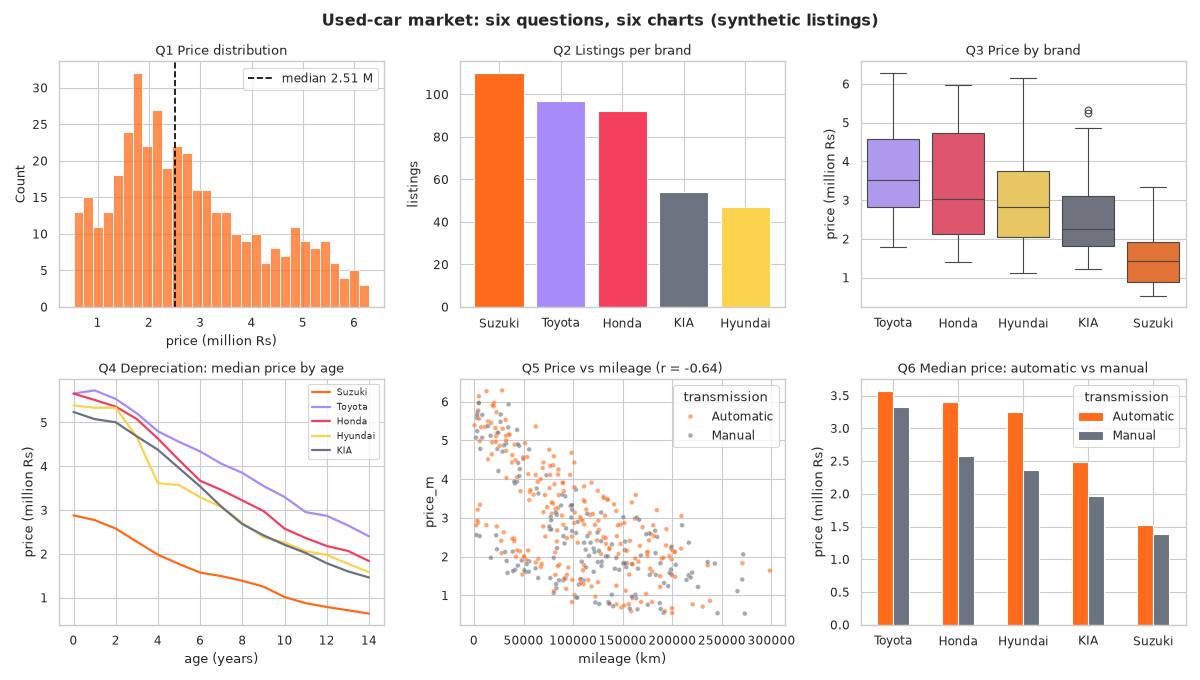

In [12]:
from IPython.display import Image, display
display(Image(filename='session-12_project_car_market_eda.png'))  # chart saved by the cell above